# [Déclarer un MLP en `keras`](https://rtavenar.github.io/deep_book/fr/content/fr/mlp.html\#declarer-un-mlp-en-keras)

In [ ]:
! pip install tensorflow
#from tensorflow.keras.layers import Dense, InputLayer
#from tensorflow.keras.models import Sequential

! pip install keras
#from keras.layers import Dense, InputLayer
#from keras.models import Sequential


In [13]:
from tensorflow.keras.layers import Dense, InputLayer
from tensorflow.keras.models import Sequential


model = Sequential([
    InputLayer(input_shape=(10, )),  #输入层：每个输入样本是一个长度为 10 的向量
    Dense(units=20, activation="relu"),  #隐藏层：这一层有 20 个神经元，从输入的 10 个特征中学习复杂的组合模式。
    Dense(units=3, activation="softmax")。 #输出层：激活函数
])

model.summary()
#第一层 Dense 有 10x20 +20(bias) = 220个参数。
#第二层 Dense 有 10x3 +30(bias) = 63个参数。
#这些“权重”和“偏置”就是模型在训练过程中需要不断优化的数据。

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 283 (1.11 KB)

 Trainable params: 283 (1.11 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import pandas as pd

boston = pd.read_csv("BostonHousing.csv")[["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "LSTAT", "MEDV"]]
boston

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0


# Travaux pratiques - Réseaux de neurones multicouches (1)

(correspond à 1 séance de TP)

Références externes utiles :

> - [Documentation NumPy](https://docs.scipy.org/doc/numpy/user/index.html)  
- [Documentation SciPy](https://docs.scipy.org/doc/scipy/reference/)  
- [Documentation MatPlotLib](http://matplotlib.org/)  
- [Site scikit-learn](http://scikit-learn.org/stable/index.html)  
- [Site langage python](https://www.python.org)  



**L’objectif** de cette séance de TP est d’illustrer le fonctionnement des perceptrons multi-couches pour un problème de classification et d’explorer l’impact des fonctions d’activation des neurones de la couche cachée, du nombre de neurones cachés et du nombre de couches cachées.

## Préparation des données

Les données employées sont constituées d’un bien connu [ensemble de 150 observations de fleurs d’iris](https://archive.ics.uci.edu/ml/datasets/iris). Pour chaque observation sont disponibles:

 - la longueur et la largeur des sépales (en cm)
 - la longueur et la largeur des pétales (en cm)
 - la variété d’iris (Iris Setosa, Iris Versicolo(u)r, Iris Virginica).

 L’objectif est de prédire la classe (la variable expliquée, ici la variété) à partir des quatre variables explicatives (longuers et largeurs des sépales et des pétales).

Dans Scikit-learn nous pouvons trouver [les données Iris déjà présentes](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html#sklearn.datasets.load_iris) et nous pouvons les charger directement avec

本文所用数据来自著名的鸢尾花数据集，共包含 150 条鸢尾花观测样本。每条样本包含：萼片长度与宽度（单位：厘米）、花瓣长度与宽度（单位：厘米），以及鸢尾花品种（山鸢尾、变色鸢尾、维吉尼亚鸢尾）。研究目标是利用 4 个特征变量（萼片与花瓣的长、宽）预测鸢尾花类别（被解释变量，即品种）。

在 Scikit-learn 中已内置鸢尾花数据集，可直接通过代码加载。

In [21]:
# importation bibliothèque numpy
import numpy as np
# importation fonction chargement données iris
from sklearn.datasets import load_iris
donnees = load_iris()

# affichage 3 premières observations
print("Affichage 3 premières observations:")
print(donnees.data[0:3,:])
donnees.data[0:3,:] #操作：切片提取前 3 行（样本）的所有列（特征）。
#预期输出：一个形状为 (3, 4) 的二维数组（Array），每一行代表一朵花的具体生物特征数值。

# dimensions matrice observations
print("\nDimensions matrice observations:")
print(donnees.data.shape)
donnees.data.shape #预期输出：(150, 4) 分别为样本总数与特征总数

# affichage étiquettes classe 3 premières observations
print("\nAffichage étiquettes classe 3 premières observations:")
print(donnees.target[0:3])
donnees.target[0:3] #操作：查看前 3 个样本的分类标签。

#预期输出：array([0, 0, 0])。0 代表第一种鸢尾花（Setosa）。

# dimensions vecteur étiquettes de classe
print("\nDimensions vecteur étiquettes de classe:")
print(donnees.target.shape) #一个长度与样本数一致的一维向量，确保每个样本都有一个对应的预测目标


Affichage 3 premières observations:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]]

Dimensions matrice observations:
(150, 4)

Affichage étiquettes classe 3 premières observations:
[0 0 0]

Dimensions vecteur étiquettes de classe:
(150,)


Ou alors, pour illustrer un cas plus général, télécharger directement à partir du site le fichier de données (en format CSV)

In [ ]:
%%bash
wget https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data

--2026-03-26 18:32:38--  https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘iris.data’

     0K ....                                                   99.3M=0s

2026-03-26 18:32:39 (99.3 MB/s) - ‘iris.data’ saved [4551]



et en lire les valeurs des quatre variables explicatives

并读取四个解释变量的数值

In [32]:
# valeurs séparées par virgule, colonnes 0 à 3, y compris 1ère ligne
data = np.loadtxt('iris.csv', delimiter=',', usecols=[0,1,2,3], skiprows=1)
print(data[0:3,:])

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]]


Les étiquettes étant sous forme textuelle dans le fichier `iris.csv` (c’est à dire `Iris-setosa`, `Iris-versicolor` et respectivement `Iris-virginica`) nous tirons profit du fait que ces trois classes se succèdent dans le fichier de données et qu’il y a exactement 50 observations par classe pour générer directement des étiquettes de classe. Nous chercherons d’abord à construire des modèles permettant de séparer les iris en **deux** classes, Iris-setosa et les autres (Iris-versicolor et Iris-virginica). Nous utilisons alors une étiquette 1 pour Iris-setosa et une étiquette 0 pour les autres :

由于 iris.csv 文件中的标签为文本格式（即分别为山鸢尾、变色鸢尾、维吉尼亚鸢尾），我们利用这三类样本在数据文件中连续排列、且每类恰好有 50 条观测值的特点，直接生成类别标签。我们首先尝试构建模型，将鸢尾花划分为两类：山鸢尾为一类，其余（变色鸢尾与维吉尼亚鸢尾）为另一类。为此，我们将山鸢尾标记为 1，其余品种标记为 0。

In [33]:
# générer étiquettes de classe 用NumPy 手动创建一个特定的类别标签向量（Target Vector）
l1c = np.ones(50, dtype=int) #生成一个长度为 50 的数组，所有元素都是 1（代表第 1 类）
l2c = np.zeros(50, dtype=int) #生成一个长度为 50 的数组，所有元素都是 0（代表第 0 类）。
target = np.concatenate((l2c, l1c, l2c)) #将三个数组按顺序连接在一起，前 50 个是 0，中间 50 个是 1，最后 50 个又是 0。

Dans le cas général il faudra employer une solution de conversion des étiquettes de classe adaptée à leur format. Une bibliothèque python qui propose de nombreuses fonctionalités de lecture et transformation des données est [pandas](https://pandas.pydata.org/docs/user_guide/index.html).

Nous pouvons visualiser les observations en nous limitant à deux ou trois variables explicatives. Par exemple, les deux dernières (longueur et largeur des pétales, en cm) :

一般情况下，需要采用适合标签格式的类别标签转换方案。Pandas 是一个提供大量数据读取与转换功能的 Python 库。

我们可以只选取两到三个解释变量来可视化观测数据。例如，选取最后两个（第三个和第四个）变量（花瓣长度与花瓣宽度，单位：厘米）：

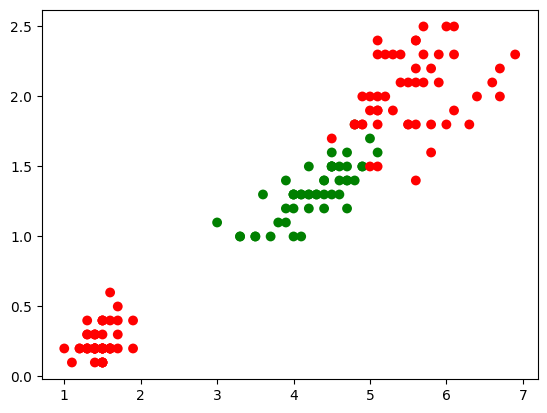

In [ ]:
#使用散点图（Scatter Plot）观察特征空间中的类别分布（par matplotlib ）。
# suivant la classe, les points affichés sont rouges ou verts (green)
cmp = np.array(['r','g']) #NumPy 字符串数组：索引 0 对应红色，索引 1 对应绿色。

# importer les fonctions d'affichage 2D
import matplotlib.pyplot as plt
plt.figure()
plt.scatter(data[:,2],data[:,3],c=cmp[target],s=50,edgecolors='none')
#取出特征矩阵的第3列（花瓣长度）和第4列（花瓣宽度）作为横纵坐标。
#c=cmp[target]：c 代表 color。根据刚才手动生成的 target 向量（前50个0，中间50个1，最后50个0）来分配颜色。
plt.show()

Le résultat (qui devrait correspondre à la figure suivante) montre que le problème de séparation visé n’est pas trivial si on se limite aux deux premières variables explicatives.

结果（应与下图一致）表明，如果仅使用**前两个解释变量**，我们要实现的分类问题并非易事。
<img src="_images/versicolorVsAutresPetales.png" alt="Affichage des données en 2D" style="width:45%;">

## Question :

Affichez en 3D les observations en vous limitant aux **3** dernières variables explicatives.

使用**最后3个解释变量**绘制观测数据的**3D可视化图**。

In [11]:
# Load data from iris.csv
import numpy as np
data = np.loadtxt('iris.csv', delimiter=',', usecols=[0,1,2,3], skiprows=1)
print('Data loaded successfully:')
print(data[0:3,:])

Data loaded successfully:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]]


In [12]:
# Generate class labels for target
import numpy as np
l1c = np.ones(50, dtype=int)
l2c = np.zeros(50, dtype=int)
target = np.concatenate((l2c, l1c, l2c))
print('Target labels generated successfully:')
print(target[0:3])

Target labels generated successfully:
[0 0 0]


In [13]:
# Define color map 'cmp'
import numpy as np
cmp = np.array(['r','g'])
print('Color map `cmp` defined successfully:')
print(cmp)

Color map `cmp` defined successfully:
['r' 'g']


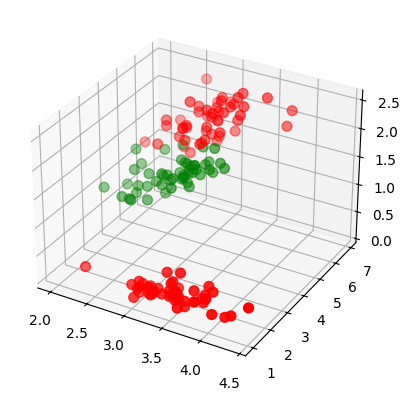

In [8]:
import matplotlib.pyplot as plt
fig = plt.figure()
ax = fig.add_subplot(projection='3d') #pour du vrai 3D, il faut passer par un objet ax

ax.scatter(data[:,1],data[:,2],data[:,3],c=cmp[target],s=50)

plt.show()

## Perceptrons multi-couches (PMC) dans Scikit-learn

Dans Scikit-learn, les PMC sont implémentés dans les classes [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) pour la classification et [MPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html) pour la régression. Nous examinons dans la suite l’utilisation des PMC pour traiter des problèmes de classification.

Les paramètres de [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) permettent de définir l’architecture du PMC (nombre de couches et de neurones dans chaque couche), les fonctions d’activation pour la(les) couche(s) cachée(s), la méthode d’optimisation (L-BFGS, SGD ou Adam avec leurs hyper-paramètres), les méthodes de régularisation (que nous examinerons dans une séance de TP ultérieure), etc.

Le nombre d’entrées est donné par le nombre de variables explicatives et dépend de leur représentation (une variable nominale sera représentée par un codage *one-hot* et donc aura autant d’entrées spécifiques qu’elle a de modalités). Le nombre de sorties est égal au **nombre de classes**, même si dans les données utilisées une seule variable représente la classe par une valeur numérique différente. La fonction d’erreur (*loss*) employée est [l’entropie croisée](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html) (*cross-entropy*, *log loss*, *logistic loss*).

在 Scikit-learn 中，多层感知器（PMC）通过 MLPClassifier 类实现分类任务，通过 MLPRegressor 类实现回归任务。下文将介绍如何使用多层感知器处理分类问题。

MLPClassifier 的参数可用于定义多层感知器的结构（网络层数与各层神经元数量）、隐藏层的激活函数、优化方法（L‑BFGS、SGD 或 Adam 及其超参数）、正则化方法（将在后续实验课中讲解）等。

输入维度由解释变量的数量决定，并取决于变量的表示方式（名义型变量需采用独热编码，其输入维度等于变量的类别数）。输出维度等于类别数量，即便在数据中仅用一个数值型变量表示类别。模型所使用的损失函数为交叉熵（cross‑entropy / log loss / logistic loss）。

### Ensembles d’apprentissage et de test

Séparons d’abord l’enseble des observations disponibles en données d’apprentissage et données de test. Pour pouvoir répéter les expérimentations, il est utile d’initialiser explicitement le générateur pseudo-aléatoire avec `np.random.seed(...)`. La fonction `train_test_split` sépare les données en deux ensembles distincts, *train* et *test*, suivant la proportion de données de *test* indiquée avec `test_size` ; la séparation est réalisée par échantillonnage aléatoire uniforme.

首先将所有可用观测样本划分为**训练集**与**测试集**。为保证实验可复现，建议使用 `np.random.seed(...)` 对伪随机数生成器进行显式初始化。
`train_test_split` 函数会根据 `test_size` 指定的测试集比例，将数据划分为互不相交的训练集与测试集；该划分通过**均匀随机抽样**实现。

In [9]:
np.random.seed(10) # initialiser le générateur pseudo-aléatoire pour pouvoir répéter l'expérience
from sklearn.model_selection import train_test_split
# X : var. explicatives, y : var. expliquée, train : apprentissage, test : test
X_train1, X_test1, y_train1, y_test1 = train_test_split(data, target, test_size=0.4)

### Construction d’un modèle pour illustration

Afin de pouvoir visualiser la frontière nonlinéaire de séparation entre classes, nous construisons d’abord un modèle avec des valeurs par défaut pour tous les hyper-paramètres sauf pour le nombre maximum d’itérations et l’optimiseur (la valeur par défaut de 200 étant insuffisante pour la méthode d’optimisation SGD - descente de gradient stochastique) en utilisant les deux premières variables explicatives. Noter que la fonction d’activation par défaut pour les neurones de la couche cachée est ReLU. Vous pouvez examiner [les valeurs par défaut des autres paramètres](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).

为了能够可视化展示类别之间的**非线性分类边界**，我们首先使用前两个解释变量构建模型，除最大迭代次数与优化器外，其余超参数均使用默认值（SGD随机梯度下降优化器的默认迭代次数200次并不足够）。需要注意的是，隐藏层神经元的默认激活函数为**ReLU**。你可以查阅[其他参数的默认值](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)。

NOTE: quand on ne spécifie pas le nombres de couches, il y en a une par défaut, avec 100 neurones

当未指定层数时，默认包含一层，包含 100 个神经元

NOTE: solver='sgd' signifie que l'algorithme d'optimisation est la descente de gradient stochastique

solver='sgd' 表示优化算法为随机梯度下降

In [17]:
from sklearn.neural_network import MLPClassifier
# donner une valeur à random_state rend possible la répétabilité
clf = MLPClassifier(solver='sgd', learning_rate_init=0.01, max_iter=10000, random_state=0)
# apprentissage avec les deux premières variables
clf.fit(X_train1[:,2:4], y_train1)

MLPClassifier(learning_rate_init=0.01, max_iter=10000, random_state=0,
              solver='sgd')

Les taux de bon classement en apprentissage (*train*) et en test sont :

In [18]:
train_score = clf.score(X_train1[:,2:4], y_train1)
print("Le score en train est {}".format(train_score))
test_score = clf.score(X_test1[:,2:4], y_test1)
print("Le score en test est {}".format(test_score))

Le score en train est 0.9444444444444444
Le score en test est 0.9666666666666667


Nous affichons les résultats : observations d’apprentissage (points pleins), observations de test (points creux), frontière de séparation. Pour déterminer la frontière de séparation, nous définissons dans le domaine de variation des deux variables explicatives une grille dense, calculons les prédictions du modèle sur tous les points de la grille et affichons un contour qui correspond aux points du plan où l’indétermination est maximale.

我们将结果进行可视化展示：训练集样本（实心点）、测试集样本（空心点）以及分类边界。为确定分类边界，我们在两个特征变量的取值范围内构建**密集网格**，对网格上所有点计算模型预测结果，并绘制出平面上**不确定性最大**的点所构成的等高线。

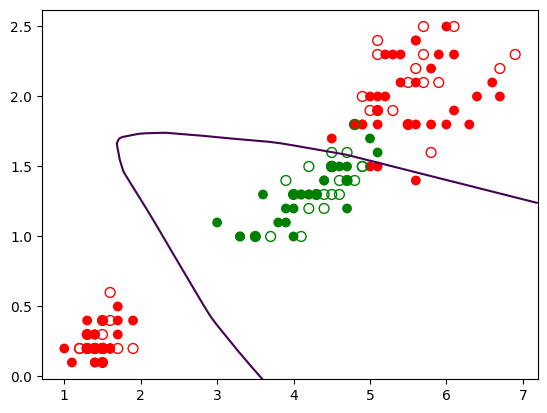

In [19]:
# créer une nouvelle figure
plt.figure()
# afficher les nuages de points d'apprentissage (pleins) et de test (creux)
plt.scatter(X_train1[:,2],X_train1[:,3],c=cmp[y_train1],s=50,edgecolors='none')
plt.scatter(X_test1[:,2],X_test1[:,3],c='none',s=50,edgecolors=cmp[y_test1])
# calculer la probabilité de sortie du MLP pour tous les points du plan
nx, ny = 200, 200
x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
xx, yy = np.meshgrid(np.linspace(x_min, x_max, nx),np.linspace(y_min, y_max, ny))
Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])
Z1 = Z[:, 1].reshape(xx.shape)
# dessiner le contour correspondant à la frontière proba = 0,5
plt.contour(xx, yy, Z1, [0.5])
plt.show()

Le résultat montre la séparation trouvée.

Nous avons employé la fonction `predict_proba` afin d’obtenir, pour chaque point de la grille définie par `xx, yy`, la prédiction du réseau sous la forme de probabilité. Le réseau a deux neurones de sortie, un donne la probabilité d’appartenance à la classe **Versicolor** et l’autre neurone la probabilité d’appartenance à l’autre classe. Avec `Z.shape` il est possible de vérifier que pour chaque observation il y a bien deux probabilités.

结果展示了模型得到的分类边界。（基于花萼特征的变色鸢尾 MLP 分类结果，除最大迭代次数 max_iter=1000 外，其余参数均使用默认设置。）

我们使用 predict_proba 函数，对由 xx 和 yy 定义的网格上的每个点，以概率形式输出神经网络的预测结果。该网络包含两个输出神经元：一个输出属于变色鸢尾类别的概率，另一个输出属于其他类别的概率。通过 Z.shape 可验证，每个观测值均对应两个概率值。

### Question :

Vérifiez que la somme des éléments de chaque ligne de Z est égale à 1 (la condition de normalisation est vérifiée).

请检查 **Z** 中每一行元素的和是否等于 1（归一化条件已满足）。


In [24]:
# rappel, Z est une matrice de 40000 lignes et 2 colonnes,
# donc chaque ligne de Z, c'est à dire Z[i], correspond à une ligne de la matrice Z
for i in range(Z.shape[0]):
    if not np.isclose(np.sum(Z[i]), 1): # np.isclose sert à comparer deux nombres flottants avec tolérance.
        print(f"La somme des éléments de la ligne {i} n'est pas égale à 1")
        break
else:
    print(f"La somme des éléments de la ligne {i} est égale à 1")

La somme des éléments de la ligne 39999 est égale à 1


Il est possible de visualiser les probabilités d’affectation à chaque classe comme des surfaces en 3 dimensions (le plan XY est celui des variables explicatives, l’axe Z correspond aux probabilités d’appartenance). Pour que la figure soit plus claire, nous ajoutons les observations avec `scatter` mais à mi-hauteur (plutôt que dans le plan Z=0).

可以将每个类别的预测概率可视化为**三维曲面**（XY 平面为特征变量所在平面，Z 轴对应类别归属概率）。为使图形更清晰，我们使用 `scatter` 函数添加样本点，并将其放置在**半高处**（而非 Z=0 平面上）。

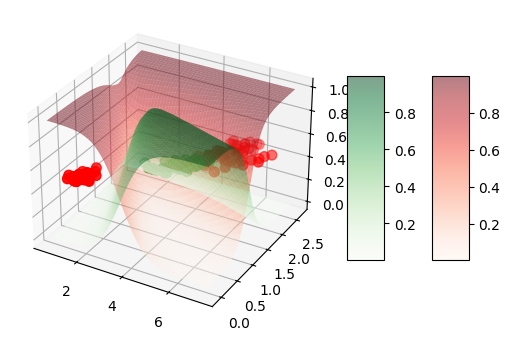

In [20]:
from matplotlib import cm
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X_train1[:,2],X_train1[:,3],0.5,c=cmp[y_train1],s=50)
ax.scatter(X_test1[:,2],X_test1[:,3],0.5,c=cmp[y_test1],s=50)
x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
xx, yy = np.meshgrid(np.linspace(x_min, x_max, nx),np.linspace(y_min, y_max, ny))
Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])
Z0 = Z[:, 0].reshape(xx.shape)
Z1 = Z[:, 1].reshape(xx.shape)
# probabilité d'appartenance à la classe Versicolor
surf1=ax.plot_surface(xx, yy, Z0, alpha=0.5, cmap=cm.Reds)
# probabilité d'appartenance à une autre classe
surf2=ax.plot_surface(xx, yy, Z1, alpha=0.5, cmap=cm.Greens)
fig.colorbar(surf1, shrink=0.5, aspect=5)
fig.colorbar(surf2, shrink=0.5, aspect=5)
plt.show()

En exécutant le programme avec python vous obtenez une figure que vous pouvez tourner pour mieux voir.

结果应与上图一致（运行 Python 程序后，你将得到一幅可旋转查看的图像，以便更清晰地观察）。

### Question :

(1) Quelle colonne de Z correspond à la probabilité d’appartenance à la classe **Versicolor** ?

Z 的哪一列对应属于 Versicolor（变色鸢尾）类别的概率？

**根据鸢尾花数据集的类别标签定义，类别 1 代表 'Versicolor'。因此，Z 数组的第二列（即 Z[:, 1]）对应于属于 'Versicolor' 类别的概率。**

(2) Il est également possible de visualiser l’évolution de l’erreur d’apprentissage au fil des itérations car les valeurs sont conservées dans l’attribut `loss_curve_` du modèle obtenu :
我们还可以可视化训练误差随迭代次数的变化情况，因为误差值会被保存在训练后模型的 **loss_curve_** 属性中：

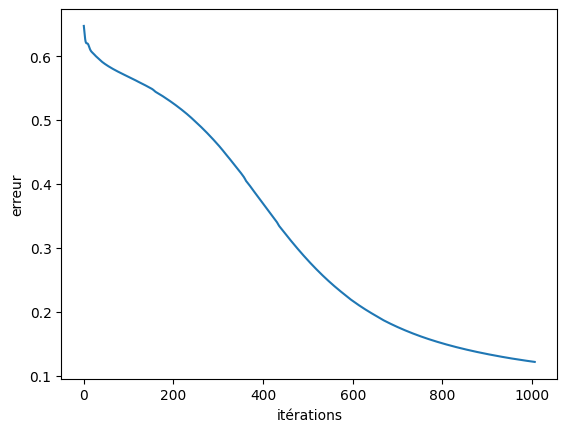

In [ ]:
plt.figure()
plt.xlabel('itérations')
plt.ylabel('erreur')
plt.plot(clf.loss_curve_)
plt.show()

On constate qu’après 1000 itérations la pente de la courbe n’est pas nulle, il est donc possible de diminuer encore l’erreur d’apprentissage en augmentant le nombre d’itérations.

可以看到，在迭代 1000 次后，曲线的斜率**并不为零**，因此**增加迭代次数**还能进一步降低训练误差。

## Exploration : fonctions d’activation, nombre couches, nombre neurones par couche

Pour mieux comprendre l’utilisation des différentes fonctions d’activations proposées pour les neurones de la (des) couche(s) cachée(s), faisons des essais avec toutes les fonctions proposées, `identity`, `logistic`, `tanh`, `relu` (déjà employée ci-dessus), en conservant les autres paramètres (sauf `max_iter=1000`) aux valeurs par défaut. Remarquons que cela change le solveur utilisé, l’algorithme par défaut pour l’optimisation étant *Adam* (une variante adaptative de la descente de gradient).

为更好地理解隐藏层神经元可用的不同激活函数，我们对所有提供的函数进行测试：identity、logistic、tanh、relu（上述已使用），其他参数（除 max_iter=1000 外）均保持默认值。需要注意的是，这会改变所使用的优化器，默认的优化算法为 Adam（梯度下降的一种自适应变体）。

In [ ]:
# identity :
clflinear = MLPClassifier(activation='identity', max_iter=1000, random_state=100)
clflinear.fit(X_train1[:,2:4], y_train1)
train_score = clflinear.score(X_train1[:,2:4], y_train1)
print("Le score en train avec identity est {}".format(train_score))
test_score = clflinear.score(X_test1[:,2:4], y_test1)
print("Le score en test avec identity est {}".format(test_score))
#
# logistic :
clfsigmoid = MLPClassifier(activation='logistic', max_iter=1000, random_state=100)
clfsigmoid.fit(X_train1[:,2:4], y_train1)
train_score = clfsigmoid.score(X_train1[:,2:4], y_train1)
print("Le score en train avec logistic est {}".format(train_score))
test_score = clfsigmoid.score(X_test1[:,2:4], y_test1)
print("Le score en test avec logistic est {}".format(test_score))
#
# tangente hyperbolique :
clftanh = MLPClassifier(activation='tanh', max_iter=1000, random_state=100)
clftanh.fit(X_train1[:,2:4], y_train1)
train_score = clftanh.score(X_train1[:,2:4], y_train1)
print("Le score en train avec tanh est {}".format(train_score))
test_score = clftanh.score(X_test1[:,2:4], y_test1)
print("Le score en test avec tanh est {}".format(test_score))

Le score en train avec identity est 0.7111111111111111
Le score en test avec identity est 0.6
Le score en train avec logistic est 0.9444444444444444
Le score en test avec logistic est 0.9666666666666667


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Le score en train avec tanh est 0.9444444444444444
Le score en test avec tanh est 0.9666666666666667


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


## Question :

Que constatez-vous ? Pourquoi les performances obtenues avec `identity` sont nettement inférieures ? Il est utile pour cela de regarder quelle frontière de séparation est trouvée.

你观察到了什么？为什么使用 **identity** 时得到的表现要差得多？为此，查看模型所找到的分类边界会很有帮助。

使用 logistic 和 tanh 激活函数的模型的训练和测试得分（约 0.94-0.96）明显高于使用 identity 激活函数的模型（约 0.6-0.7）。

这是因为 identity 激活函数是线性的 (linéaire)。当分类问题需要非线性决策边界时（像鸢尾花数据集这样类之间可能存在非线性重叠的数据），线性激活函数在隐藏层将无法学习到这些复杂的非线性关系，从而导致性能显著下降。而 logistic 和 tanh 是非线性激活函数(fonctions d'activation non linéaires)，能够让模型学习更复杂的决策边界。

若需要，可要求gemini绘制使用 identity 激活函数的模型（clflinear）的决策边界。

## Question :

Avec la fonction d’activation ReLU pour les neurones de la couche cachée, faites varier le nombre de neurones de cette couche entre 2 et 200. Que constatez-vous ? Il peut être nécessaire d’augmenter la valeur de `max_iter` pour laisser l’apprentissage se poursuivre jusqu’à un minimum de l’erreur.

将隐藏层神经元设置为 ReLU 激活函数，将该层神经元数量在 **2 到 200** 之间进行调整。你观察到了什么？可能需要增大 **max_iter** 的取值，让训练持续进行直到误差达到最小值。

探究隐藏层神经元数量的影响 (Exploration de l'impact du nombre de neurones dans la couche cachée)

观察点 (Observations) :

- 过少神经元 (Trop peu de neurones) : 如果神经元数量太少，模型可能无法学习到足够复杂的模式，导致训练和测试分数都较低（欠拟合）。
- 适中神经元 (Nombre de neurones approprié) : 随着神经元数量的增加，模型性能通常会提高，因为它能捕捉到更多的数据特征。
- 过多神经元 (Trop de neurones) : 神经元数量过多可能会导致模型过拟合训练数据，即在训练集上表现良好但在测试集上表现下降。同时，过多的神经元也会增加训练时间和计算成本。
请运行以下代码并观察不同神经元数量对训练和测试分数的影响。

在隐藏层神经元数量在2到200之间调整的实验中，我们观察到以下几点：

- 神经元数量较少时（如2个）：模型性能较差，训练分数和测试分数都比较低（Train score: 0.6667, Test score: 0.5667），这表明模型可能处于欠拟合状态，无法捕捉数据中的复杂模式。
- 随着神经元数量的增加（如5个到100个）：模型性能显著提升，训练和测试分数普遍较高。例如，在10个神经元时，训练分数为0.9444，测试分数为0.9500；在100个神经元时，训练分数为0.9444，测试分数为0.9667。这表明模型能够学习到更复杂的决策边界。
- 神经元数量过多（如200个）：在本次实验中，200个神经元的测试分数达到了最高的0.9833，训练分数也达到0.9556。虽然这在当前任务中表现良好，但通常情况下，神经元数量过多可能会增加计算成本，并有潜在的过拟合风险（尽管在这个特定数据集上，可能还需要更多的数据或更复杂的模型才能观察到明显的过拟合）。

关于 ConvergenceWarning (收敛警告)： 您可能注意到在某些情况下出现了 ConvergenceWarning。这意味着模型在达到 max_iter=2000 次迭代后，优化过程尚未完全收敛。这表明对于这些特定的神经元配置，模型可能需要更多的迭代次数才能达到误差的最小值。在实际应用中，如果遇到此警告，可以尝试增大 max_iter 的值，以确保模型充分学习。

Exploration de l'impact du nombre de neurones dans la couche cachée (ReLU activation):

Testing with 2 neurons in the hidden layer...
  Train score: 0.6667
  Test score: 0.5667

Testing with 5 neurons in the hidden layer...


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


  Train score: 0.9111
  Test score: 0.8667

Testing with 10 neurons in the hidden layer...


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


  Train score: 0.9444
  Test score: 0.9500

Testing with 20 neurons in the hidden layer...
  Train score: 0.7111
  Test score: 0.6000

Testing with 50 neurons in the hidden layer...
  Train score: 0.9444
  Test score: 0.9500

Testing with 100 neurons in the hidden layer...
  Train score: 0.9444
  Test score: 0.9667

Testing with 200 neurons in the hidden layer...
  Train score: 0.9556
  Test score: 0.9833


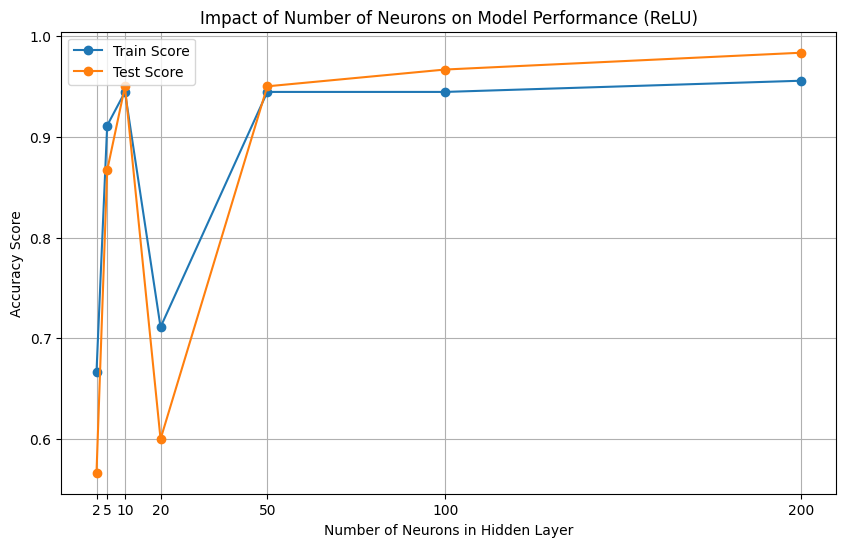

In [22]:
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import numpy as np

neuron_counts = [2, 5, 10, 20, 50, 100, 200]

train_scores_relu = []
test_scores_relu = []

print("Exploration de l'impact du nombre de neurones dans la couche cachée (ReLU activation):")
for neurons in neuron_counts:
    print(f"\nTesting with {neurons} neurons in the hidden layer...")
    # Use ReLU activation, a higher max_iter for convergence, and a random_state for reproducibility
    clf_relu = MLPClassifier(hidden_layer_sizes=(neurons,), activation='relu', max_iter=2000, random_state=42)
    clf_relu.fit(X_train1[:,2:4], y_train1)

    train_score = clf_relu.score(X_train1[:,2:4], y_train1)
    test_score = clf_relu.score(X_test1[:,2:4], y_test1)

    train_scores_relu.append(train_score)
    test_scores_relu.append(test_score)

    print(f"  Train score: {train_score:.4f}")
    print(f"  Test score: {test_score:.4f}")

# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(neuron_counts, train_scores_relu, label='Train Score', marker='o')
plt.plot(neuron_counts, test_scores_relu, label='Test Score', marker='o')
plt.xlabel('Number of Neurons in Hidden Layer')
plt.ylabel('Accuracy Score')
plt.title('Impact of Number of Neurons on Model Performance (ReLU)')
plt.xticks(neuron_counts)
plt.grid(True)
plt.legend()
plt.show()

## Question :

Avec la fonction d’activation ReLU pour les neurones des couches cachées et en conservant 10 neurones par couche cachée, faites varier le nombre de couches cachées entre 2 et 5. Que constatez-vous ? Il peut être nécessaire d’augmenter la valeur de `max_iter` pour laisser l’apprentissage se poursuivre jusqu’à un minimum de l’erreur.

将隐藏层神经元的激活函数设为 **ReLU**，并保持每个隐藏层的神经元数量为 **10**，把隐藏层数量在 **2 到 5** 之间进行调整。你观察到了什么？可能需要增大 `max_iter` 的值，让训练持续进行直到误差达到最小值。

观察点 (Observations) :

- 增加层数：通常，增加隐藏层可以帮助模型学习更复杂的特征和非线性关系。在某些情况下，这可能导致模型性能的提升。
- 过多的层数：然而，过多的隐藏层也可能导致过拟合，模型在训练集上表现良好，但在测试集上性能下降。此外，模型会变得更难训练，计算成本也会增加，并可能出现梯度消失/爆炸等问题。
- 收敛警告：由于模型复杂度的增加，您可能会看到更多的 **ConvergenceWarning**，这表明模型需要更多的迭代才能完全收敛。在这种情况下，进一步增加 max_iter 可能会有所帮助。